In [1]:
import os
import gc
import pickle

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager

from sklearn.calibration import calibration_curve
import statsmodels.api as sm

from statsmodels.iolib.smpickle import load_pickle
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_colwidth', 0)

In [3]:
import os
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

In [4]:
individual = ['Member_DOB_Age_Qty',
              'Member_Has_ALS_Diag_Ind','Member_Has_AMI_Diag_Ind',
              'Member_Has_Anxiety_Disorders_Diag_Ind','Member_Has_Asthma_Diag_Ind','Member_Has_Burns_Diag_Ind',
 'Member_Has_Cancer_Diag_Ind','Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind','Member_Has_CHF_Diag_Ind',
 'Member_Has_CAD_Diag_Ind','Member_Has_Cerobrovascular_Disease_Diag_Ind','Member_Has_CIDP_Diag_Ind',
 'Member_Has_CKD_Diag_Ind','Member_Has_Congenital_Hydrocephalus_Diag_Ind',
              'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
              'Member_Has_COPD_Diag_Ind','Member_Has_Crohns_Diag_Ind',
 'Member_Has_Cystic_Fibrosis_Diag_Ind',
 'Member_Has_Depression_Diag_Ind',
 'Member_Has_Dermatomyositis_Diag_Ind',
 'Member_Has_Diabetes_Diag_Ind',
 'Member_Has_Epilepsy_Diag_Ind',
 'Member_Has_ESRD_Diag_Ind',
 'Member_Has_Gaucher_Disease_Diag_Ind',
 'Member_Has_Hemophilia_Diag_Ind',
 'Member_Has_Hepatitis_Diag_Ind',
 'Member_Has_HIV_Diag_Ind',
 'Member_Has_HTN_Diag_Ind',
 'Member_Has_Liver_Disease_Diag_Ind',
 'Member_Has_Lupus_Diag_Ind',
 'Member_Has_Multiple_Sclerosis_Diag_Ind',
 'Member_Has_Myasthenia_Gravis_Diag_Ind',
 'Member_Has_Myositis_Diag_Ind',
 'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
 'Member_Has_Osteoarthritis_Diag_Ind',
 'Member_Has_Other_Mental_Health_Diag_Ind',
 'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
 'Member_Has_Parkinsons_Diag_Ind',
 'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
 'Member_Has_Polymyositis_Diag_Ind',
 'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
 'Member_Has_RA_Diag_Ind',
 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
 'Member_Has_Scleroderma_Diag_Ind',
 'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
 'Member_Has_Spina_Bifida_Diag_Ind',
 'Member_Has_Spinal_Cord_Injury_Diag_Ind',
 'Member_Has_Substance_Abuse_Disorder_Diag_Ind','Member_Has_Ulcerative_Colitis_Diag_Ind', 
                'Member_Is_Exchange_Member_Ind', 
                'Product_Is_ACA_Plan_Ind','Product_Is_Certified_QHP_Ind',
                'Product_Is_Supplemental_Ind',
                'Member_Marital_Status_Current_Divorced',
 'Member_Marital_Status_Current_Married',
 'Member_Marital_Status_Current_Single',
 'Member_Marital_Status_Current_Unknown',
 'Member_Marital_Status_Current_Widow(er)',
 'Product_Metal_Level_Bronze',
 'Product_Metal_Level_Gold',
 'Product_Metal_Level_Not Applicable',
 'Product_Metal_Level_Platinum',
 'Product_Metal_Level_Silver',
 'Product_Type_Not Applicable',
 'Product_Type_Other',
 'Product_Type_POS',
 'Product_Type_PPO',
 'Member_Gender_Current_Female',
 'Race_Black or African American',
 'Race_Hispanic or Latino',
 'Race_Missing',
 'Race_Others',
 'Race_White']

In [5]:
individual_sdoh = ['Member_DOB_Age_Qty',
                 'Member_Has_ALS_Diag_Ind',  'Member_Has_AMI_Diag_Ind',
 'Member_Has_Anxiety_Disorders_Diag_Ind','Member_Has_Asthma_Diag_Ind','Member_Has_Burns_Diag_Ind',
 'Member_Has_Cancer_Diag_Ind','Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind','Member_Has_CHF_Diag_Ind',
 'Member_Has_CAD_Diag_Ind','Member_Has_Cerobrovascular_Disease_Diag_Ind','Member_Has_CIDP_Diag_Ind',
 'Member_Has_CKD_Diag_Ind','Member_Has_Congenital_Hydrocephalus_Diag_Ind',
                    'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
 'Member_Has_COPD_Diag_Ind','Member_Has_Crohns_Diag_Ind',
 'Member_Has_Cystic_Fibrosis_Diag_Ind',
 'Member_Has_Depression_Diag_Ind',
 'Member_Has_Dermatomyositis_Diag_Ind',
 'Member_Has_Diabetes_Diag_Ind',
 'Member_Has_Epilepsy_Diag_Ind',
 'Member_Has_ESRD_Diag_Ind',
 'Member_Has_Gaucher_Disease_Diag_Ind',
 'Member_Has_Hemophilia_Diag_Ind',
 'Member_Has_Hepatitis_Diag_Ind',
 'Member_Has_HIV_Diag_Ind',
 'Member_Has_HTN_Diag_Ind',
 'Member_Has_Liver_Disease_Diag_Ind',
 'Member_Has_Lupus_Diag_Ind',
 'Member_Has_Multiple_Sclerosis_Diag_Ind',
 'Member_Has_Myasthenia_Gravis_Diag_Ind',
 'Member_Has_Myositis_Diag_Ind',
 'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
 'Member_Has_Osteoarthritis_Diag_Ind',
 'Member_Has_Other_Mental_Health_Diag_Ind',
 'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
 'Member_Has_Parkinsons_Diag_Ind',
 'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
 'Member_Has_Polymyositis_Diag_Ind',
 'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
 'Member_Has_RA_Diag_Ind',
 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
 'Member_Has_Scleroderma_Diag_Ind',
 'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
 'Member_Has_Spina_Bifida_Diag_Ind',
 'Member_Has_Spinal_Cord_Injury_Diag_Ind',
 'Member_Has_Substance_Abuse_Disorder_Diag_Ind','Member_Has_Ulcerative_Colitis_Diag_Ind', 
                'Member_Is_Exchange_Member_Ind', 
                'Product_Is_ACA_Plan_Ind','Product_Is_Certified_QHP_Ind',
                'Product_Is_Supplemental_Ind',
 'ACS_PCT_ENGL_NOT_ALL',
 'ACS_PCT_FEMALE',
 'ACS_PCT_FOREIGN_BORN',
 'ACS_PCT_LIMIT_ENGLISH',
 'ACS_PCT_NON_CITIZEN',
 'ACS_PCT_1UP_PERS_1ROOM',
 'ACS_PCT_AGE_65UP',
 'ACS_PCT_ASIAN',
 'ACS_PCT_BLACK',
 'ACS_PCT_HISPAN',
 'ACS_PCT_WHITE',
 'ACS_PCT_DISABLE',
 'ACS_HH_SIZE',
 'ACS_PCT_DIVORCE_SEPARAT',
 'ACS_PCT_HH_NO_FUEL',
 'ACS_PCT_ADMIN',
 'ACS_PCT_CONSTRUCT',
 'ACS_PCT_EDUC',
 'ACS_PCT_FINANCE',
 'ACS_PCT_MANUFACT',
 'ACS_PCT_NATURE',
 'ACS_PCT_PROFESS',
 'ACS_PCT_RETAIL',
 'ACS_PCT_TRANSPORT',
 'ACS_PCT_UNEMPLOY',
 'ACS_PCT_NONVA_POOR',
 'ACS_GINI_INDEX',
 'ACS_MEDIAN_HH_INCOME',
 'ACS_PCT_FOOD_STAMP',
 'ACS_PCT_HH_PUB_ASSIST',
 'ACS_PCT_BACHELOR_DGR',
 'ACS_PCT_LT_HS',
 'ACS_PCT_GRP_QRT',
 'CCBP_RATE_CS_PER_1000',
 'ACS_PCT_NO_VEH',
 'ACS_PCT_MEDICAID_ANY64',
 'ACS_PCT_PRIVATE_ANY64',
 'ACS_PCT_PRIVATE_EMPL64',
 'ACS_PCT_UNINSURED64',
 'ACS_PCT_UNINSURED','any_open_park','count_open_parks',
 'count_tri_facilities',
                   'Member_Marital_Status_Current_Unknown',
                   'Member_Marital_Status_Current_Divorced',
 'Member_Marital_Status_Current_Married',
 'Member_Marital_Status_Current_Single',
 'Member_Marital_Status_Current_Widow(er)',
 'Product_Metal_Level_Bronze',
 'Product_Metal_Level_Gold',
 'Product_Metal_Level_Platinum',
 'Product_Metal_Level_Silver',
                   'Product_Metal_Level_Not Applicable',
  'Product_Type_Not Applicable',
 'Product_Type_Other',
 'Product_Type_POS',
 'Product_Type_PPO',
 'Member_Gender_Current_Female',
 'Race_Black or African American',
 'Race_Hispanic or Latino',
 'Race_Missing',
 'Race_Others',
 'Race_White']

In [6]:
individual_sdi = ['Member_DOB_Age_Qty','Member_Has_ALS_Diag_Ind','Member_Has_AMI_Diag_Ind',
              'Member_Has_Anxiety_Disorders_Diag_Ind','Member_Has_Asthma_Diag_Ind','Member_Has_Burns_Diag_Ind',
 'Member_Has_Cancer_Diag_Ind','Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind','Member_Has_CHF_Diag_Ind',
 'Member_Has_CAD_Diag_Ind','Member_Has_Cerobrovascular_Disease_Diag_Ind','Member_Has_CIDP_Diag_Ind',
 'Member_Has_CKD_Diag_Ind','Member_Has_Congenital_Hydrocephalus_Diag_Ind',
              'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
              'Member_Has_COPD_Diag_Ind','Member_Has_Crohns_Diag_Ind',
 'Member_Has_Cystic_Fibrosis_Diag_Ind',
 'Member_Has_Depression_Diag_Ind',
 'Member_Has_Dermatomyositis_Diag_Ind',
 'Member_Has_Diabetes_Diag_Ind',
 'Member_Has_Epilepsy_Diag_Ind',
 'Member_Has_ESRD_Diag_Ind',
 'Member_Has_Gaucher_Disease_Diag_Ind',
 'Member_Has_Hemophilia_Diag_Ind',
 'Member_Has_Hepatitis_Diag_Ind',
 'Member_Has_HIV_Diag_Ind',
 'Member_Has_HTN_Diag_Ind',
 'Member_Has_Liver_Disease_Diag_Ind',
 'Member_Has_Lupus_Diag_Ind',
 'Member_Has_Multiple_Sclerosis_Diag_Ind',
 'Member_Has_Myasthenia_Gravis_Diag_Ind',
 'Member_Has_Myositis_Diag_Ind',
 'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
 'Member_Has_Osteoarthritis_Diag_Ind',
 'Member_Has_Other_Mental_Health_Diag_Ind',
 'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
 'Member_Has_Parkinsons_Diag_Ind',
 'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
 'Member_Has_Polymyositis_Diag_Ind',
 'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
 'Member_Has_RA_Diag_Ind',
 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
 'Member_Has_Scleroderma_Diag_Ind',
 'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
 'Member_Has_Spina_Bifida_Diag_Ind',
 'Member_Has_Spinal_Cord_Injury_Diag_Ind',
 'Member_Has_Substance_Abuse_Disorder_Diag_Ind','Member_Has_Ulcerative_Colitis_Diag_Ind', 
                'Member_Is_Exchange_Member_Ind', 
                'Product_Is_ACA_Plan_Ind','Product_Is_Certified_QHP_Ind',
                'Product_Is_Supplemental_Ind',
                'Member_Marital_Status_Current_Divorced',
 'Member_Marital_Status_Current_Married',
 'Member_Marital_Status_Current_Single',
 'Member_Marital_Status_Current_Unknown',
 'Member_Marital_Status_Current_Widow(er)',
 'Product_Metal_Level_Bronze',
 'Product_Metal_Level_Gold',
 'Product_Metal_Level_Not Applicable',
 'Product_Metal_Level_Platinum',
 'Product_Metal_Level_Silver',
  'Product_Type_Not Applicable',
 'Product_Type_Other',
 'Product_Type_POS',
 'Product_Type_PPO',
 'Member_Gender_Current_Female',
 'Race_Black or African American',
 'Race_Hispanic or Latino',
 'Race_Missing',
 'Race_Others',
 'Race_White',
                  'sdi']

In [7]:
individual_sdoh_sdi = individual_sdoh + [
    col for col in individual_sdi if col not in individual_sdoh
]

feature_sets = {
    "individual": individual,
    "individual_sdoh": individual_sdoh,
    "individual_sdi": individual_sdi,
    "individual_sdoh_sdi": individual_sdoh_sdi
}

model_labels = {
    "individual": "Ind Features",
    "individual_sdoh": "Ind + SDoH Features",
    "individual_sdi": "Ind + SDI Features",
    "individual_sdoh_sdi": "Ind + SDoH + SDI Features"
}

for name, features in feature_sets.items():
    print(name, len(features))

individual 73
individual_sdoh 116
individual_sdi 74
individual_sdoh_sdi 117


# Poisson Model Plots

In [8]:
MODEL_DIR = "../results/poisson_intensity_sample"
# MODEL_DIR = "../results/xgboost_poisson_full"
SAVE_DIR = "../results/poisson_intensity_sample"
# SAVE_DIR = "../results/xgboost_poisson_full"

In [ ]:

MODEL_ORDER = [
    "individual",
    "individual_sdoh",
    "individual_sdi",
    "individual_sdoh_sdi"
]

MAIN_MODEL_ORDER = [
    "individual",
    "individual_sdoh"
]

MODEL_LABELS_SHORT = {
    "individual": "Individual",
    "individual_sdoh": "Individual + nSDoH",
    "individual_sdi": "Individual + SDI",
    "individual_sdoh_sdi": "Individual + nSDoH + SDI"
}

MODEL_COLORS = {
    "individual": "#0057B8",          # blue
    "individual_sdoh": "#E31A1C",     # orange/red
    "individual_sdi": "#33A02C",      # green
    "individual_sdoh_sdi": "#FF7F00"  # purple
}

GROUP_COLORS = {
    "Full cohort": "#4D4D4D",
    "Top neighborhood SDoH burden": "#D55E00",
    "Bottom neighborhood SDoH burden": "#7A7A7A"
}

FIGSIZE_SINGLE = (5.2, 4.0)
FIGSIZE_WIDE = (6.2, 4.2)

AXIS_LABEL_SIZE = 11
TICK_LABEL_SIZE = 10
LEGEND_SIZE = 9
LINE_WIDTH = 2.0
MARKER_SIZE = 4

def apply_paper_style(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis="both", labelsize=TICK_LABEL_SIZE)
    ax.set_title("")
    return ax

In [10]:
x_train = pd.read_csv("../data_processed/x_train_nb_sample.csv")
y_train = pd.read_csv("../data_processed/y_train_nb_sample.csv")

In [11]:
x_test_intensity = pd.read_csv("../data_processed/x_test_nb_sample.csv")
y_test_intensity = pd.read_csv("../data_processed/y_test_nb_sample.csv")

In [12]:
# ============================================================
# Observed outcome columns in y_test
# ============================================================

PCP_OBS_COL = "pcp_intensity"
ER_OBS_COL = "er_intensity"

print("y_test columns:")
print(y_test_intensity.columns.tolist())

y_test columns:
['Member_Wid', 'pcp_intensity', 'er_intensity']


In [13]:
# Preprocessing before validation
reference_dummy_cols = [
    "Member_Marital_Status_Current_Unknown",
    "Product_Metal_Level_Not Applicable",
    "Product_Type_Not Applicable",
    "Race_Missing"
]

def prepare_x_for_count_model(x_df, features):
    X = x_df[features].copy()
    X = X.astype(float)

    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(0)

    X = sm.add_constant(X, has_constant="add")

    constant_cols = [
        col for col in X.columns
        if col != "const" and X[col].nunique(dropna=False) <= 1
    ]

    if len(constant_cols) > 0:
        X = X.drop(columns=constant_cols)

    drop_cols = [c for c in reference_dummy_cols if c in X.columns]

    if len(drop_cols) > 0:
        X = X.drop(columns=drop_cols)

    return X

In [14]:
# For Statsmodel Poisson
# Getting Test Predictions
def load_poisson_predictions(outcome_name, outcome_col):
    
    y_test_count = y_test_intensity[outcome_col].astype(int)
    pred_dict = {}
    
    for suffix, features in feature_sets.items():
        
        model_path = os.path.join(
            MODEL_DIR,
            f"poisson_{outcome_name}_{suffix}_sample.pkl"
        )
        
        print("Loading:", model_path)
        
        poisson_result = load_pickle(model_path)
        
        X_test = prepare_x_for_count_model(x_test_intensity, features)
        X_test = X_test.reindex(columns=poisson_result.params.index, fill_value=0)
        
        y_pred_count = poisson_result.predict(X_test)
        
        pred_dict[suffix] = y_pred_count
        
        print(suffix, "min:", y_pred_count.min(), "max:", y_pred_count.max())
        
        del poisson_result, X_test
        gc.collect()
    
    return y_test_count, pred_dict

# For XGBoost poisson
# import xgboost as xgb

# def load_poisson_predictions(outcome_name, outcome_col):
    
#     y_test_count = y_test_intensity[outcome_col].astype(int)
#     pred_dict = {}
    
#     for suffix, features in feature_sets.items():
        
#         model_path = os.path.join(
#             MODEL_DIR,
#             f"xgb_poisson_{outcome_name}_{suffix}_full.pkl"
#         )
        
#         print("Loading:", model_path)
        
#         model = load_pickle(model_path)
#         features_used = model.feature_names
#         X_test = (
#             x_test_intensity[features]
#             .reindex(columns=features_used, fill_value=0)
#             .replace([np.inf, -np.inf], np.nan)
#             .fillna(0)
#             .astype(np.float32)
#         )
        
#         dtest = xgb.DMatrix(
#             X_test,
#             feature_names=features_used
#         )
        
#         try:
#             y_pred_count = model.predict(
#                 dtest,
#                 iteration_range=(0, model.best_iteration + 1)
#             )
#         except Exception:
#             y_pred_count = model.predict(dtest)
        
#         pred_dict[suffix] = y_pred_count
        
#         print(
#             suffix,
#             "min:", y_pred_count.min(),
#             "max:", y_pred_count.max(),
#             "mean:", y_pred_count.mean()
#         )
#         print("actual mean:", y_test_count.mean())
#         print("pred mean:", y_pred_count.mean())
#         print("actual max:", y_test_count.max())
#         print("pred max:", y_pred_count.max())
        
#         del model, X_test, dtest
#         gc.collect()
    
#     return y_test_count, pred_dict

In [15]:
# Creating global variables for predictions
pcp_obs_count, pcp_pred_dict = load_poisson_predictions(
    outcome_name="pcp_count",
    outcome_col="pcp_intensity"
)

er_obs_count, er_pred_dict = load_poisson_predictions(
    outcome_name="er_count",
    outcome_col="er_intensity"
)

Loading: ../results/poisson_intensity_sample/poisson_pcp_count_individual_sample.pkl
individual min: 5.594461659914409e-13 max: 18.95433927538797
Loading: ../results/poisson_intensity_sample/poisson_pcp_count_individual_sdoh_sample.pkl
individual_sdoh min: 5.163392156605056e-13 max: 18.969836549579405
Loading: ../results/poisson_intensity_sample/poisson_pcp_count_individual_sdi_sample.pkl
individual_sdi min: 5.506844870400991e-13 max: 19.083126247231416
Loading: ../results/poisson_intensity_sample/poisson_pcp_count_individual_sdoh_sdi_sample.pkl
individual_sdoh_sdi min: 5.151941907406939e-13 max: 18.927874178702076
Loading: ../results/poisson_intensity_sample/poisson_er_count_individual_sample.pkl
individual min: 3.531031242305625e-13 max: 10.072300326075094
Loading: ../results/poisson_intensity_sample/poisson_er_count_individual_sdoh_sample.pkl
individual_sdoh min: 3.4980924726876874e-13 max: 9.72931695903415
Loading: ../results/poisson_intensity_sample/poisson_er_count_individual_sdi

In [16]:
# ============================================================
# Same selected nSDoH columns used in train for PFA
# ============================================================

#selected nSDoH columns used for PCP PFA 
PCP_NSDOH_COLS = [
    'ACS_PCT_HISPAN',
    'ACS_PCT_NATURE',
    'ACS_PCT_TRANSPORT',
    'count_tri_facilities',
    'ACS_PCT_PROFESS',
    'ACS_PCT_RETAIL',
    'ACS_PCT_NO_VEH',
    'ACS_PCT_BACHELOR_DGR',
    'ACS_MEDIAN_HH_INCOME',
    'ACS_PCT_ENGL_NOT_ALL'
]

#selected nSDoH columns used for ER PFA 
ER_NSDOH_COLS = [
    'count_open_parks',
    'ACS_PCT_CONSTRUCT',
    'ACS_PCT_AGE_65UP',
    'ACS_PCT_UNINSURED64',
    'ACS_PCT_UNINSURED',
    'ACS_PCT_PRIVATE_ANY64',
    'ACS_PCT_ADMIN',
    'ACS_PCT_LIMIT_ENGLISH',
    'ACS_PCT_PRIVATE_EMPL64',
    'ACS_PCT_HISPAN'
]

In [ ]:
def create_x_test_pfa_score(
    x_train,
    x_test,
    nsdoh_cols,
    score_name,
    save_path=None,
    random_state=42
):
    """
    Fit scaler + PFA on x_train nSDoH columns.
    Transform x_test using same fitted scaler + PFA.
    Apply the same direction logic used earlier:
    higher score = more nSDoH disadvantage.
    """
    
    missing_train = [c for c in nsdoh_cols if c not in x_train.columns]
    missing_test = [c for c in nsdoh_cols if c not in x_test.columns]
    
    if missing_train:
        raise ValueError(f"Missing nSDoH columns in x_train: {missing_train}")
    
    if missing_test:
        raise ValueError(f"Missing nSDoH columns in x_test: {missing_test}")
    
    # ----------------------------
    # Train nSDoH matrix
    # ----------------------------
    X_train_nsdoh = (
        x_train[nsdoh_cols]
        .replace([np.inf, -np.inf], np.nan)
        .apply(pd.to_numeric, errors="coerce")
    )
    
    train_medians = X_train_nsdoh.median()
    X_train_nsdoh = X_train_nsdoh.fillna(train_medians)
    
    # ----------------------------
    # Test nSDoH matrix
    # ----------------------------
    X_test_nsdoh = (
        x_test[nsdoh_cols]
        .replace([np.inf, -np.inf], np.nan)
        .apply(pd.to_numeric, errors="coerce")
        .fillna(train_medians)
    )
    
    # ----------------------------
    # Scale: fit on train, transform test
    # ----------------------------
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_nsdoh)
    X_test_scaled = scaler.transform(X_test_nsdoh)
    
    # ----------------------------
    # PFA: fit on train, transform test
    # ----------------------------
    pfa = FactorAnalysis(n_components=1, random_state=random_state)
    
    train_score = pfa.fit_transform(X_train_scaled).ravel()
    test_score = pfa.transform(X_test_scaled).ravel()
    
    # ----------------------------
    # Direction check
    # ----------------------------
    pfa_loadings = pd.DataFrame({
        "feature": nsdoh_cols,
        "loading": pfa.components_[0]
    })
    
    pfa_loadings["abs_loading"] = pfa_loadings["loading"].abs()
    
    bad_direction_cols = [
        "ACS_PCT_UNEMPLOY",
        "ACS_PCT_NONVA_POOR",
        "ACS_PCT_FOOD_STAMP",
        "ACS_PCT_HH_PUB_ASSIST",
        "ACS_PCT_LT_HS",
        "ACS_PCT_NO_VEH",
        "ACS_PCT_UNINSURED64",
        "ACS_PCT_UNINSURED",
        "ACS_PCT_1UP_PERS_1ROOM",
        "ACS_PCT_LIMIT_ENGLISH",
        "ACS_PCT_NON_CITIZEN",
        "ACS_GINI_INDEX"
    ]
    
    bad_present = [
        c for c in bad_direction_cols
        if c in pfa_loadings["feature"].values
    ]
    
    flipped = False
    
    if len(bad_present) > 0:
        
        mean_bad_loading = pfa_loadings.loc[
            pfa_loadings["feature"].isin(bad_present),
            "loading"
        ].mean()
        
        print("Mean loading for disadvantage-like columns:", mean_bad_loading)
        
        if mean_bad_loading < 0:
            print("Flipping PFA score so higher = more disadvantage.")
            
            train_score = -train_score
            test_score = -test_score
            
            pfa_loadings["loading"] = -pfa_loadings["loading"]
            flipped = True
    
    else:
        
        if "ACS_MEDIAN_HH_INCOME" in pfa_loadings["feature"].values:
            
            income_loading = pfa_loadings.loc[
                pfa_loadings["feature"] == "ACS_MEDIAN_HH_INCOME",
                "loading"
            ].iloc[0]
            
            print("Income loading:", income_loading)
            
            if income_loading > 0:
                print("Flipping PFA score because income positive means higher score may reflect advantage.")
                
                train_score = -train_score
                test_score = -test_score
                
                pfa_loadings["loading"] = -pfa_loadings["loading"]
                flipped = True
        
        else:
            print("No disadvantage direction columns or ACS_MEDIAN_HH_INCOME found.")
    
    # Recalculate abs loading after possible flip
    pfa_loadings["abs_loading"] = pfa_loadings["loading"].abs()
    pfa_loadings = pfa_loadings.sort_values("abs_loading", ascending=False)
    
    # ----------------------------
    # Standardize using train score mean/std
    # ----------------------------
    train_mean = train_score.mean()
    train_std = train_score.std()
    
    if train_std == 0:
        raise ValueError("Train PFA score standard deviation is 0. Cannot standardize.")
    
    train_score_std = (train_score - train_mean) / train_std
    test_score_std = (test_score - train_mean) / train_std
    
    # 85th percentile threshold based on training PFA distribution
    pfa_threshold_85 = np.quantile(train_score_std, 0.85)

    print("Training PFA 85th percentile threshold:", pfa_threshold_85)
    print(
        "Percentage of test observations above threshold:",
        (test_score_std >= pfa_threshold_85).mean() * 100
    )
    
    print("\nPFA score created:", score_name)
    print("Number of nSDoH columns:", len(nsdoh_cols))
    print("Sign flipped:", flipped)
    print("Train standardized mean/std:", train_score_std.mean(), train_score_std.std())
    print("Test standardized mean/std:", test_score_std.mean(), test_score_std.std())
    
    
    return test_score_std, pfa_threshold_85, pfa_loadings

In [18]:
pcp_test_pfa_score, pcp_pfa_threshold_85, pcp_pfa_loadings = create_x_test_pfa_score(
    x_train=x_train,
    x_test=x_test_intensity,
    nsdoh_cols=PCP_NSDOH_COLS,
    score_name="pcp_count_nSDoH_pfa_score_test",
    random_state=42
)

er_test_pfa_score, er_pfa_threshold_85, er_pfa_loadings = create_x_test_pfa_score(
    x_train=x_train,
    x_test=x_test_intensity,
    nsdoh_cols=ER_NSDOH_COLS,
    score_name="er_count_nSDoH_pfa_score_test",
    random_state=42
)

Mean loading for disadvantage-like columns: -0.2927993999967921
Flipping PFA score so higher = more disadvantage.
Training PFA 85th percentile threshold: 1.011836873895038
Percentage of test observations above threshold: 14.974069522071614

PFA score created: pcp_count_nSDoH_pfa_score_test
Number of nSDoH columns: 10
Sign flipped: True
Train standardized mean/std: -2.937498917747042e-18 0.9999999999999998
Test standardized mean/std: 0.0017112952387443032 0.9986521130120354
Mean loading for disadvantage-like columns: 0.766347711689601
Training PFA 85th percentile threshold: 1.0536832479669402
Percentage of test observations above threshold: 14.912139406015164

PFA score created: er_count_nSDoH_pfa_score_test
Number of nSDoH columns: 10
Sign flipped: False
Train standardized mean/std: -2.405814019448847e-18 1.0
Test standardized mean/std: -0.0002363840817136116 0.9994190181617078


In [19]:
# ============================================================
# Central Poisson analysis objects
# ============================================================

POISSON_ANALYSES = {
    "PCP": {
        "observed": np.asarray(pcp_obs_count),
        "predictions": pcp_pred_dict,
        "pfa_score": np.asarray(pcp_test_pfa_score),
        "pfa_threshold_85": pcp_pfa_threshold_85,
        "outcome_label": "PCP count"
    },
    "ER": {
        "observed": np.asarray(er_obs_count),
        "predictions": er_pred_dict,
        "pfa_score": np.asarray(er_test_pfa_score),
        "pfa_threshold_85": er_pfa_threshold_85,
        "outcome_label": "ER count"
    }
}

**Calibration Plot**

In [20]:
def make_calibration_bins(observed_count, predicted_count, n_bins=10):
    dat = pd.DataFrame({
        "observed": np.asarray(observed_count, dtype=float),
        "predicted": np.asarray(predicted_count, dtype=float)
    })

    dat = (
        dat.replace([np.inf, -np.inf], np.nan)
           .dropna()
           .copy()
    )

    dat = dat[
        (dat["observed"] >= 0)
        & (dat["predicted"] >= 0)
    ].copy()

    dat["bin"] = pd.qcut(
        dat["predicted"].rank(method="first"),
        q=n_bins,
        labels=False,
        duplicates="drop"
    )

    out = (
        dat.groupby("bin")
        .agg(
            mean_predicted=("predicted", "mean"),
            mean_observed=("observed", "mean"),
            sd_observed=("observed", "std"),
            n=("observed", "size")
        )
        .reset_index()
    )

    out["se_observed"] = out["sd_observed"] / np.sqrt(out["n"])
    out["ci_lower"] = (out["mean_observed"] - 1.96 * out["se_observed"]).clip(lower=0)
    out["ci_upper"] = out["mean_observed"] + 1.96 * out["se_observed"]

    return out

In [21]:
def calculate_calibration_slope_intercept(observed_count, predicted_count):
    dat = pd.DataFrame({
        "observed": np.asarray(observed_count, dtype=float),
        "predicted": np.asarray(predicted_count, dtype=float)
    })

    dat = (
        dat.replace([np.inf, -np.inf], np.nan)
           .dropna()
           .copy()
    )

    dat = dat[
        (dat["observed"] >= 0)
        & (dat["predicted"] > 0)
    ].copy()

    dat["log_predicted"] = np.log(dat["predicted"])

    X = sm.add_constant(dat["log_predicted"], has_constant="add")

    model = sm.GLM(
        dat["observed"],
        X,
        family=sm.families.Poisson()
    )

    result = model.fit(cov_type="HC0")
    conf = result.conf_int()

    mean_observed = dat["observed"].mean()
    mean_predicted = dat["predicted"].mean()

    return {
        "N": len(dat),
        "mean_observed": mean_observed,
        "mean_predicted": mean_predicted,
        "observed_to_predicted_ratio": mean_observed / mean_predicted,
        "calibration_intercept": result.params["const"],
        "intercept_ci_lower": conf.loc["const", 0],
        "intercept_ci_upper": conf.loc["const", 1],
        "calibration_slope": result.params["log_predicted"],
        "slope_ci_lower": conf.loc["log_predicted", 0],
        "slope_ci_upper": conf.loc["log_predicted", 1]
    }

In [22]:
def plot_calibration_full_vs_top_burden(
    outcome_key,
    analysis,
    model_order=MAIN_MODEL_ORDER,
    n_bins=10,
    save_dir=SAVE_DIR
):
    observed = analysis["observed"]
    pfa_score = analysis["pfa_score"]
    threshold = analysis["pfa_threshold_85"]

    top_mask = pfa_score >= threshold

    sample_defs = {
        "Full cohort": np.ones(len(observed), dtype=bool),
        "Top neighborhood SDoH burden": top_mask
    }

    line_styles = {
        "Full cohort": "-",
        "Top neighborhood SDoH burden": "--"
    }

    markers = {
        "Full cohort": "o",
        "Top neighborhood SDoH burden": "s"
    }

    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)

    all_max = 0
    metrics_rows = []

    for model_key in model_order:
        predicted = np.asarray(analysis["predictions"][model_key])
        model_label = MODEL_LABELS_SHORT[model_key]
        color = MODEL_COLORS[model_key]

        for sample_name, sample_mask in sample_defs.items():
            y_sample = observed[sample_mask]
            pred_sample = predicted[sample_mask]

            cal_bins = make_calibration_bins(
                observed_count=y_sample,
                predicted_count=pred_sample,
                n_bins=n_bins
            )

            ax.plot(
                cal_bins["mean_predicted"],
                cal_bins["mean_observed"],
                linestyle=line_styles[sample_name],
                marker=markers[sample_name],
                linewidth=LINE_WIDTH,
                markersize=MARKER_SIZE,
                color=color,
                label=f"{model_label}, {sample_name}"
            )

            ax.fill_between(
                cal_bins["mean_predicted"].to_numpy(),
                cal_bins["ci_lower"].to_numpy(),
                cal_bins["ci_upper"].to_numpy(),
                color=color,
                alpha=0.10,
                linewidth=0
            )

            row = calculate_calibration_slope_intercept(
                observed_count=y_sample,
                predicted_count=pred_sample
            )

            row["Outcome"] = outcome_key
            row["Sample"] = sample_name
            row["Model"] = model_label
            metrics_rows.append(row)

            all_max = max(
                all_max,
                cal_bins["mean_predicted"].max(),
                cal_bins["mean_observed"].max(),
                cal_bins["ci_upper"].max()
            )

    axis_max = all_max * 1.08

    ax.plot(
        [0, axis_max],
        [0, axis_max],
        linestyle=":",
        linewidth=1.8,
        color="black",
        label="Perfect calibration"
    )

    ax.set_xlim(0, axis_max)
    ax.set_ylim(0, axis_max)

    ax.set_xlabel("Mean predicted count", fontsize=AXIS_LABEL_SIZE)
    ax.set_ylabel("Mean observed count", fontsize=AXIS_LABEL_SIZE)

    apply_paper_style(ax)

    ax.legend(
        frameon=False,
        fontsize=LEGEND_SIZE,
        loc="best"
    )

    fig.tight_layout()

    plot_path = os.path.join(
        save_dir,
        f"{outcome_key.lower()}_calibration_full_vs_top_burden.png"
    )

    fig.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()

    metrics_df = pd.DataFrame(metrics_rows)

    metrics_path = os.path.join(
        save_dir,
        f"{outcome_key.lower()}_calibration_full_vs_top_burden_metrics.csv"
    )

    metrics_df.to_csv(metrics_path, index=False)

    print("Saved plot:", plot_path)
    print("Saved metrics:", metrics_path)

    display(metrics_df)

    return metrics_df

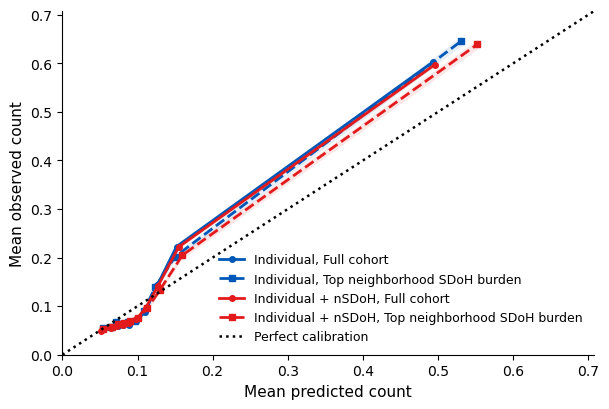

Saved plot: ../results/poisson_intensity_sample/pcp_calibration_full_vs_top_burden.png
Saved metrics: ../results/poisson_intensity_sample/pcp_calibration_full_vs_top_burden_metrics.csv


,N,mean_observed,mean_predicted,observed_to_predicted_ratio,calibration_intercept,intercept_ci_lower,intercept_ci_upper,calibration_slope,slope_ci_lower,slope_ci_upper,Outcome,Sample,Model
0,1359597,0.141770,0.134209,1.056335,0.055254,0.045419,0.065089,1.000274,0.995198,1.005350,PCP,Full cohort,Individual
1,203587,0.145613,0.136522,1.066592,0.045084,0.022298,0.067871,0.987852,0.976003,0.999701,PCP,Top neighborhood SDoH burden,Individual
2,1359597,0.141770,0.134476,1.054244,0.047914,0.038186,0.057643,0.996988,0.991966,1.002010,PCP,Full cohort,Individual + nSDoH
3,203587,0.145613,0.142154,1.024338,-0.001788,-0.024193,0.020616,0.983372,0.971518,0.995226,PCP,Top neighborhood SDoH burden,Individual + nSDoH


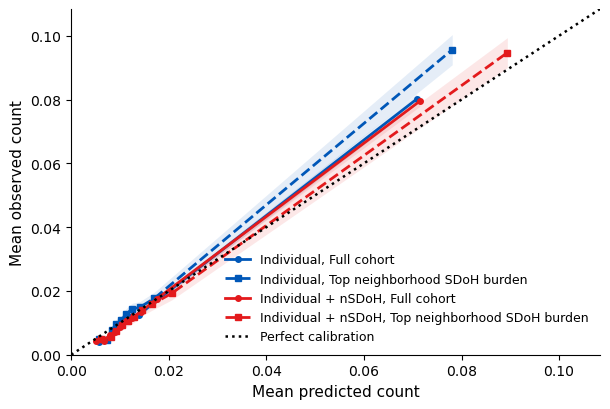

Saved plot: ../results/poisson_intensity_sample/er_calibration_full_vs_top_burden.png
Saved metrics: ../results/poisson_intensity_sample/er_calibration_full_vs_top_burden_metrics.csv


,N,mean_observed,mean_predicted,observed_to_predicted_ratio,calibration_intercept,intercept_ci_lower,intercept_ci_upper,calibration_slope,slope_ci_lower,slope_ci_upper,Outcome,Sample,Model
0,1359597,0.016326,0.016558,0.985988,-0.077819,-0.119779,-0.035859,0.981915,0.971242,0.992588,ER,Full cohort,Individual
1,202745,0.019300,0.017371,1.111042,-0.028792,-0.120713,0.063129,0.961231,0.937537,0.984926,ER,Top neighborhood SDoH burden,Individual
2,1359597,0.016326,0.016579,0.984764,-0.090265,-0.131315,-0.049214,0.978640,0.968181,0.989099,ER,Full cohort,Individual + nSDoH
3,202745,0.019300,0.019930,0.968411,-0.159367,-0.247984,-0.070750,0.961625,0.937946,0.985303,ER,Top neighborhood SDoH burden,Individual + nSDoH


In [23]:
pcp_calibration_metrics = plot_calibration_full_vs_top_burden(
    outcome_key="PCP",
    analysis=POISSON_ANALYSES["PCP"]
)

er_calibration_metrics = plot_calibration_full_vs_top_burden(
    outcome_key="ER",
    analysis=POISSON_ANALYSES["ER"]
)

In [26]:
def plot_calibration_full_vs_top_burden_1x2(
    analyses,
    model_order=MAIN_MODEL_ORDER,
    n_bins=10,
    save_dir=SAVE_DIR
):
    outcome_order = ["PCP", "ER"]

    # Blue/orange model colors
    model_colors = {
        "individual": "#0057B8",          # blue
        "individual_sdoh": "#E31A1C"
    }

    line_styles = {
        "Full cohort": "-",
        "Top 15% neighborhood SDoH burden": "--"
    }

    markers = {
        "Full cohort": "o",
        "Top 15% neighborhood SDoH burden": "s"
    }

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(8.8, 4.0),
        sharex=False,
        sharey=False
    )

    metrics_rows = []
    legend_handles = {}

    panel_labels = {
        "PCP": "a",
        "ER": "b"
    }

    for ax, outcome_key in zip(axes, outcome_order):

        analysis = analyses[outcome_key]

        observed = np.asarray(analysis["observed"])
        pfa_score = np.asarray(analysis["pfa_score"])
        threshold = analysis["pfa_threshold_85"]

        top_mask = pfa_score >= threshold

        sample_defs = {
            "Full cohort": np.ones(len(observed), dtype=bool),
            "Top 15% neighborhood SDoH burden": top_mask
        }

        all_max = 0

        # Store slope values for this panel
#         slope_lines = ["Calibration slope"]
        # Store handles and slope labels for inset legend
        slope_handles = []
        slope_labels = []

        for model_key in model_order:

            predicted = np.asarray(analysis["predictions"][model_key])
            model_label = MODEL_LABELS_SHORT[model_key]
            color = model_colors.get(model_key, MODEL_COLORS[model_key])

            for sample_name, sample_mask in sample_defs.items():

                y_sample = observed[sample_mask]
                pred_sample = predicted[sample_mask]

                cal_bins = make_calibration_bins(
                    observed_count=y_sample,
                    predicted_count=pred_sample,
                    n_bins=n_bins
                )

                legend_label = f"{model_label}, {sample_name}"

                line = ax.plot(
                    cal_bins["mean_predicted"],
                    cal_bins["mean_observed"],
                    linestyle=line_styles[sample_name],
                    marker=markers[sample_name],
                    linewidth=LINE_WIDTH,
                    markersize=MARKER_SIZE,
                    color=color,
                    label=legend_label
                )[0]

                ax.fill_between(
                    cal_bins["mean_predicted"].to_numpy(),
                    cal_bins["ci_lower"].to_numpy(),
                    cal_bins["ci_upper"].to_numpy(),
                    color=color,
                    alpha=0.06,
                    linewidth=0
                )

                legend_handles[legend_label] = line

                row = calculate_calibration_slope_intercept(
                    observed_count=y_sample,
                    predicted_count=pred_sample
                )

                row["Outcome"] = outcome_key
                row["Sample"] = sample_name
                row["Model"] = model_label
                row["Top 15% cutoff"] = threshold
                row["N top 15%"] = int(top_mask.sum()) if sample_name != "Full cohort" else np.nan

                metrics_rows.append(row)

                # Add compact slope label for panel box
                short_model = {
                    "Individual": "Ind",
                    "Individual + nSDoH": "Ind+nSDoH"
                }.get(model_label, model_label)

                short_sample = {
                    "Full cohort": "Full",
                    "Top 15% neighborhood SDoH burden": "Top15"
                }[sample_name]

#                 slope_lines.append(
#                     f"{short_model}, {short_sample}: {row['calibration_slope']:.3f}"
#                 )
                slope_handles.append(line)

                slope_labels.append(
                    f"{short_model}, {short_sample}: {row['calibration_slope']:.3f}"
                )

                all_max = max(
                    all_max,
                    cal_bins["mean_predicted"].max(),
                    cal_bins["mean_observed"].max(),
                    cal_bins["ci_upper"].max()
                )

        axis_max = all_max * 1.08

        perfect_line = ax.plot(
            [0, axis_max],
            [0, axis_max],
            linestyle=":",
            linewidth=1.8,
            color="black",
            label="Perfect calibration"
        )[0]
        
        slope_handles.append(perfect_line)
        slope_labels.append("Perfect calibration")

        ax.set_xlim(0, axis_max)
        ax.set_ylim(0, axis_max)

        apply_paper_style(ax)

        ax.set_xlabel("Mean predicted count", fontsize=AXIS_LABEL_SIZE)
        ax.set_ylabel("Mean observed count", fontsize=AXIS_LABEL_SIZE)

        # Panel label
        ax.text(
            0.03,
            0.96,
            panel_labels[outcome_key],
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10.5,
            fontweight="bold"
        )

#         # Slope box inside each panel
#         ax.text(
#             0.96,
#             0.04,
#             "\n".join(slope_lines),
#             transform=ax.transAxes,
#             ha="right",
#             va="bottom",
#             fontsize=7.0,
#             linespacing=1.25,
#             zorder=30,
#             bbox=dict(
#                 facecolor="white",
#                 edgecolor="#666666",
#                 linewidth=0.6,
#                 alpha=0.95,
#                 boxstyle="round,pad=0.30"
#             )
#         )
        # Combined calibration-slope legend inside each panel
        ax.legend(
            slope_handles,
            slope_labels,
            title="Calibration slope",
            loc="lower right",
            frameon=True,
            facecolor="white",
            edgecolor="#666666",
            framealpha=0.95,
            fontsize=7.0,
            title_fontsize=7.2,
            handlelength=2.2,
            handletextpad=0.6,
            labelspacing=0.35,
            borderpad=0.45
        )

#     legend_handles["Perfect calibration"] = perfect_line

#     fig.legend(
#         list(legend_handles.values()),
#         list(legend_handles.keys()),
#         loc="lower center",
#         ncol=3,
#         frameon=False,
#         fontsize=LEGEND_SIZE,
#         bbox_to_anchor=(0.5, -0.03)
#     )

    fig.tight_layout(rect=[0, 0.18, 1, 1])
#     fig.tight_layout()
    plot_path = os.path.join(
        save_dir,
        "calibration_full_vs_top_burden_pcp_er_1x2.png"
    )

    fig.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    metrics_df = pd.DataFrame(metrics_rows)

    metrics_path = os.path.join(
        save_dir,
        "calibration_full_vs_top_burden_pcp_er_1x2_metrics.csv"
    )

    metrics_df.to_csv(metrics_path, index=False)

    print("Saved plot:", plot_path)
    print("Saved metrics:", metrics_path)

    display(metrics_df)

    return metrics_df

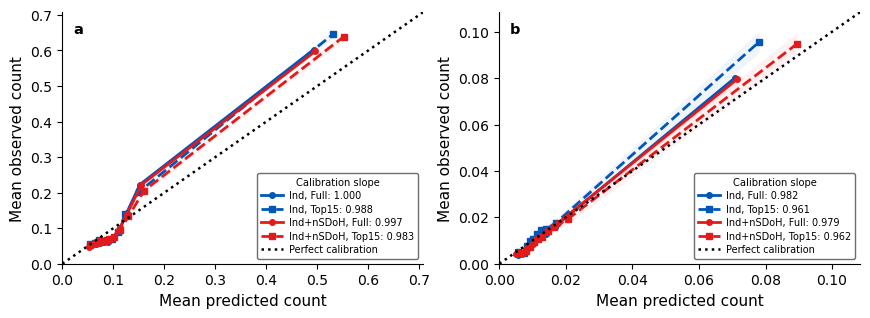

Saved plot: ../results/poisson_intensity_sample/calibration_full_vs_top_burden_pcp_er_1x2.png
Saved metrics: ../results/poisson_intensity_sample/calibration_full_vs_top_burden_pcp_er_1x2_metrics.csv


,N,mean_observed,mean_predicted,observed_to_predicted_ratio,calibration_intercept,intercept_ci_lower,intercept_ci_upper,calibration_slope,slope_ci_lower,slope_ci_upper,Outcome,Sample,Model,Top 15% cutoff,N top 15%
0,1359597,0.141770,0.134209,1.056335,0.055254,0.045419,0.065089,1.000274,0.995198,1.005350,PCP,Full cohort,Individual,1.011837,NaN
1,203587,0.145613,0.136522,1.066592,0.045084,0.022298,0.067871,0.987852,0.976003,0.999701,PCP,Top 15% neighborhood SDoH burden,Individual,1.011837,203587.0
2,1359597,0.141770,0.134476,1.054244,0.047914,0.038186,0.057643,0.996988,0.991966,1.002010,PCP,Full cohort,Individual + nSDoH,1.011837,NaN
3,203587,0.145613,0.142154,1.024338,-0.001788,-0.024193,0.020616,0.983372,0.971518,0.995226,PCP,Top 15% neighborhood SDoH burden,Individual + nSDoH,1.011837,203587.0
4,1359597,0.016326,0.016558,0.985988,-0.077819,-0.119779,-0.035859,0.981915,0.971242,0.992588,ER,Full cohort,Individual,1.053683,NaN
5,202745,0.019300,0.017371,1.111042,-0.028792,-0.120713,0.063129,0.961231,0.937537,0.984926,ER,Top 15% neighborhood SDoH burden,Individual,1.053683,202745.0
6,1359597,0.016326,0.016579,0.984764,-0.090265,-0.131315,-0.049214,0.978640,0.968181,0.989099,ER,Full cohort,Individual + nSDoH,1.053683,NaN
7,202745,0.019300,0.019930,0.968411,-0.159367,-0.247984,-0.070750,0.961625,0.937946,0.985303,ER,Top 15% neighborhood SDoH burden,Individual + nSDoH,1.053683,202745.0


In [27]:
calibration_full_vs_top_burden_metrics = plot_calibration_full_vs_top_burden_1x2(
    analyses=POISSON_ANALYSES,
    model_order=MAIN_MODEL_ORDER,
    n_bins=10,
    save_dir=SAVE_DIR
)

In [24]:
def get_top_burden_mask(
    analysis,
    top_percent,
    use_training_cutoff=True
):
    """
    Returns mask for top X% neighborhood SDoH burden group.

    For top 15%, uses existing training-derived 85th percentile cutoff
    if available, so it matches earlier analysis exactly.

    For top 10% and top 20%, this uses training PFA score if available.
    If not available, it falls back to test PFA score quantiles.
    """

    test_score = np.asarray(analysis["pfa_score"])

    # Keep existing top 15% cutoff exactly same as before
    if top_percent == 15 and "pfa_threshold_85" in analysis:
        cutoff = analysis["pfa_threshold_85"]
        mask = test_score >= cutoff
        return mask, cutoff

    quantile = 1 - (top_percent / 100)

    if use_training_cutoff and "pfa_train_score" in analysis:
        cutoff_source = np.asarray(analysis["pfa_train_score"])
    else:
        cutoff_source = test_score

    cutoff_source = cutoff_source[np.isfinite(cutoff_source)]

    cutoff = np.quantile(
        cutoff_source,
        quantile
    )

    mask = test_score >= cutoff

    return mask, cutoff

In [25]:
def get_calibration_axis_max(
    analysis,
    sample_masks,
    model_order=MODEL_ORDER,
    n_bins=10
):
    """
    Calculates common axis max across multiple sample masks and all models.
    This makes sure related panels use exactly same x/y scale.
    """

    observed = np.asarray(analysis["observed"])
    pred_dict = analysis["predictions"]

    axis_max = 0

    for sample_mask in sample_masks:

        sample_mask = np.asarray(sample_mask).astype(bool)

        for model_key in model_order:

            predicted = np.asarray(pred_dict[model_key])

            cal_bins = make_calibration_bins(
                observed_count=observed[sample_mask],
                predicted_count=predicted[sample_mask],
                n_bins=n_bins
            )

            axis_max = max(
                axis_max,
                cal_bins["mean_predicted"].max(),
                cal_bins["mean_observed"].max(),
                cal_bins["ci_upper"].max()
            )

    return axis_max * 1.08

In [26]:
def format_calibration_slope_inset(slope_rows):
    """
    Creates compact text for calibration slope inset inside each panel.
    """
    label_map = {
        "Individual": "Ind",
        "Individual + nSDoH": "Ind+nSDoH",
        "Individual + SDI": "Ind+SDI",
        "Individual + nSDoH + SDI": "All"
    }

    lines = ["Slope"]
    for row in slope_rows:
        short_label = label_map.get(row["Model"], row["Model"])
        lines.append(f"{short_label}: {row['calibration_slope']:.3f}")

    return "\n".join(lines)

In [27]:
def plot_calibration_full_and_top15_2x2(
    analyses,
    model_order=MODEL_ORDER,
    n_bins=10,
    save_dir=SAVE_DIR,
    same_axis_all_panels=False
):

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(8.2, 6.4),
        sharex=False,
        sharey=False
    )

    panel_specs = [
        {
            "ax": axes[0, 0],
            "outcome_key": "PCP",
            "sample_label": "Full cohort",
            "top_percent": None,
            "panel_label": ""
        },
        {
            "ax": axes[0, 1],
            "outcome_key": "PCP",
            "sample_label": "Top 15% neighborhood SDoH burden",
            "top_percent": 15,
            "panel_label": ""
        },
        {
            "ax": axes[1, 0],
            "outcome_key": "ER",
            "sample_label": "Full cohort",
            "top_percent": None,
            "panel_label": ""
        },
        {
            "ax": axes[1, 1],
            "outcome_key": "ER",
            "sample_label": "Top 15% neighborhood SDoH burden",
            "top_percent": 15,
            "panel_label": ""
        }
    ]

    # --------------------------------------------------------
    # Build exact same axis scale for full vs top15 within each outcome
    # --------------------------------------------------------

    axis_max_by_outcome = {}

    for outcome_key, analysis in analyses.items():

        observed = np.asarray(analysis["observed"])

        full_mask = np.ones(len(observed), dtype=bool)

        top15_mask, top15_cutoff = get_top_burden_mask(
            analysis=analysis,
            top_percent=15
        )

        axis_max_by_outcome[outcome_key] = get_calibration_axis_max(
            analysis=analysis,
            sample_masks=[full_mask, top15_mask],
            model_order=model_order,
            n_bins=n_bins
        )

    if same_axis_all_panels:
        common_axis = max(axis_max_by_outcome.values())
        axis_max_by_outcome = {
            key: common_axis for key in axis_max_by_outcome.keys()
        }

    # --------------------------------------------------------
    # Plot panels
    # --------------------------------------------------------

    legend_handles = {}
    metrics_rows = []

    for spec in panel_specs:
        
        panel_slope_lines = ["Calibration slope"]
        ax = spec["ax"]
        outcome_key = spec["outcome_key"]
        analysis = analyses[outcome_key]

        observed = np.asarray(analysis["observed"])
        panel_slope_rows = []

        if spec["top_percent"] is None:
            sample_mask = np.ones(len(observed), dtype=bool)
            cutoff = np.nan
        else:
            sample_mask, cutoff = get_top_burden_mask(
                analysis=analysis,
                top_percent=spec["top_percent"]
            )

        for model_key in model_order:

            model_label = MODEL_LABELS_SHORT[model_key]
            color = MODEL_COLORS[model_key]

            predicted = np.asarray(analysis["predictions"][model_key])

            cal_bins = make_calibration_bins(
                observed_count=observed[sample_mask],
                predicted_count=predicted[sample_mask],
                n_bins=n_bins
            )

            line = ax.plot(
                cal_bins["mean_predicted"],
                cal_bins["mean_observed"],
                marker="o",
                linewidth=LINE_WIDTH,
                markersize=MARKER_SIZE,
                color=color,
                label=model_label
            )[0]

            ax.fill_between(
                cal_bins["mean_predicted"].to_numpy(),
                cal_bins["ci_lower"].to_numpy(),
                cal_bins["ci_upper"].to_numpy(),
                color=color,
                alpha=0.06,
                linewidth=0
            )

            legend_handles[model_label] = line

            metrics = calculate_calibration_slope_intercept(
                observed_count=observed[sample_mask],
                predicted_count=predicted[sample_mask]
            )

            metrics["Outcome"] = outcome_key
            metrics["Sample"] = spec["sample_label"]
            metrics["Model"] = model_label
            metrics["Cutoff"] = cutoff
            metrics_rows.append(metrics)
            # Add slope value for this model to the panel text box
            short_model_label = {
                "Individual": "Ind",
                "Individual + nSDoH": "Ind+nSDoH",
                "Individual + SDI": "Ind+SDI",
                "Individual + nSDoH + SDI": "All"
            }.get(model_label, model_label)

            panel_slope_lines.append(
                f"{short_model_label}: {metrics['calibration_slope']:.3f}"
            )

        axis_max = axis_max_by_outcome[outcome_key]

        ax.plot(
            [0, axis_max],
            [0, axis_max],
            linestyle=":",
            linewidth=1.8,
            color="black",
            label="Perfect calibration"
        )

        ax.set_xlim(0, axis_max)
        ax.set_ylim(0, axis_max)

        apply_paper_style(ax)
        
        # Add calibration slope values inside panel
        slope_text = "\n".join(panel_slope_lines)

        ax.text(
            0.96,
            0.04,
            slope_text,
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=7.2,
            linespacing=1.25,
            zorder=30,
            bbox=dict(
                facecolor="white",
                edgecolor="#666666",
                linewidth=0.6,
                alpha=0.95,
                boxstyle="round,pad=0.30"
            )
        )
        
        ax.text(
            0.02,
            0.96,
            spec["panel_label"],
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            fontweight="bold"
        )

        ax.set_xlabel("Mean predicted count", fontsize=AXIS_LABEL_SIZE)
        ax.set_ylabel("Mean observed count", fontsize=AXIS_LABEL_SIZE)

    # --------------------------------------------------------
    # Single legend
    # --------------------------------------------------------

    perfect_line = plt.Line2D(
        [0],
        [0],
        linestyle=":",
        linewidth=1.8,
        color="black",
        label="Perfect calibration"
    )

    handles = list(legend_handles.values()) + [perfect_line]
    labels = list(legend_handles.keys()) + ["Perfect calibration"]

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=LEGEND_SIZE,
        bbox_to_anchor=(0.5, -0.02)
    )

    fig.tight_layout(rect=[0, 0.07, 1, 1])

    plot_path = os.path.join(
        save_dir,
        "poisson_calibration_full_and_top15_2x2_all_models.png"
    )

    fig.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    metrics_df = pd.DataFrame(metrics_rows)

    metrics_path = os.path.join(
        save_dir,
        "poisson_calibration_full_and_top15_2x2_metrics.csv"
    )

    metrics_df.to_csv(metrics_path, index=False)

    print("Saved plot:", plot_path)
    print("Saved metrics:", metrics_path)

    display(metrics_df)

    return metrics_df

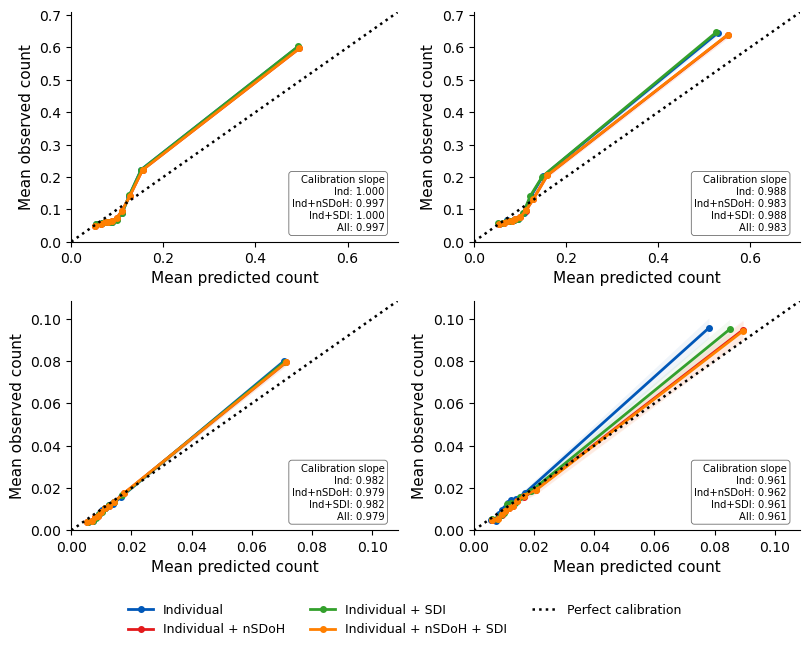

Saved plot: ../results/poisson_intensity_sample/poisson_calibration_full_and_top15_2x2_all_models.png
Saved metrics: ../results/poisson_intensity_sample/poisson_calibration_full_and_top15_2x2_metrics.csv


,N,mean_observed,mean_predicted,observed_to_predicted_ratio,calibration_intercept,intercept_ci_lower,intercept_ci_upper,calibration_slope,slope_ci_lower,slope_ci_upper,Outcome,Sample,Model,Cutoff
0,1359597,0.141770,0.134209,1.056335,0.055254,0.045419,0.065089,1.000274,0.995198,1.005350,PCP,Full cohort,Individual,NaN
1,1359597,0.141770,0.134476,1.054244,0.047914,0.038186,0.057643,0.996988,0.991966,1.002010,PCP,Full cohort,Individual + nSDoH,NaN
2,1359597,0.141770,0.134204,1.056374,0.055327,0.045490,0.065165,1.000296,0.995219,1.005374,PCP,Full cohort,Individual + SDI,NaN
3,1359597,0.141770,0.134477,1.054231,0.047967,0.038238,0.057695,0.997028,0.992006,1.002050,PCP,Full cohort,Individual + nSDoH + SDI,NaN
4,203587,0.145613,0.136522,1.066592,0.045084,0.022298,0.067871,0.987852,0.976003,0.999701,PCP,Top 15% neighborhood SDoH burden,Individual,1.011837
5,203587,0.145613,0.142154,1.024338,-0.001788,-0.024193,0.020616,0.983372,0.971518,0.995226,PCP,Top 15% neighborhood SDoH burden,Individual + nSDoH,1.011837
6,203587,0.145613,0.135368,1.075683,0.052909,0.030037,0.075782,0.987501,0.975654,0.999349,PCP,Top 15% neighborhood SDoH burden,Individual + SDI,1.011837
7,203587,0.145613,0.142026,1.025259,-0.000721,-0.023134,0.021691,0.983489,0.971635,0.995343,PCP,Top 15% neighborhood SDoH burden,Individual + nSDoH + SDI,1.011837
8,1359597,0.016326,0.016558,0.985988,-0.077819,-0.119779,-0.035859,0.981915,0.971242,0.992588,ER,Full cohort,Individual,NaN
9,1359597,0.016326,0.016579,0.984764,-0.090265,-0.131315,-0.049214,0.978640,0.968181,0.989099,ER,Full cohort,Individual + nSDoH,NaN


In [28]:
calibration_2x2_metrics = plot_calibration_full_and_top15_2x2(
    analyses=POISSON_ANALYSES,
    model_order=MODEL_ORDER,
    n_bins=10,
    save_dir=SAVE_DIR,
    same_axis_all_panels=False
)

In [29]:
def calculate_prediction_metrics(observed_count, predicted_count):
    dat = pd.DataFrame({
        "observed": np.asarray(observed_count, dtype=float),
        "predicted": np.asarray(predicted_count, dtype=float)
    })

    dat = (
        dat.replace([np.inf, -np.inf], np.nan)
           .dropna()
           .copy()
    )

    dat = dat[
        (dat["observed"] >= 0)
        & (dat["predicted"] >= 0)
    ].copy()

    mae = np.mean(np.abs(dat["observed"] - dat["predicted"]))
    rmse = np.sqrt(np.mean((dat["observed"] - dat["predicted"]) ** 2))

    mean_observed = dat["observed"].mean()
    mean_predicted = dat["predicted"].mean()

    return {
        "N": len(dat),
        "mean_observed": mean_observed,
        "mean_predicted": mean_predicted,
        "observed_to_predicted_ratio": mean_observed / mean_predicted,
        "MAE": mae,
        "RMSE": rmse
    }


def make_prediction_performance_table(
    outcome_key,
    analysis,
    model_order=MODEL_ORDER
):
    observed = analysis["observed"]
    predicted_dict = analysis["predictions"]
    pfa_score = analysis["pfa_score"]
    threshold = analysis["pfa_threshold_85"]

    sample_defs = {
        "Full cohort": np.ones(len(observed), dtype=bool),
        "Top 15% neighborhood SDoH burden": pfa_score >= threshold
    }

    rows = []

    for sample_name, sample_mask in sample_defs.items():
        baseline_rmse = None
        baseline_mae = None

        for model_key in model_order:
            metrics = calculate_prediction_metrics(
                observed_count=observed[sample_mask],
                predicted_count=np.asarray(predicted_dict[model_key])[sample_mask]
            )

            row = {
                "Outcome": outcome_key,
                "Sample": sample_name,
                "Model": MODEL_LABELS_SHORT[model_key],
                **metrics
            }

            if model_key == "individual":
                baseline_rmse = metrics["RMSE"]
                baseline_mae = metrics["MAE"]

            row["RMSE improvement vs baseline"] = (
                baseline_rmse - metrics["RMSE"]
                if baseline_rmse is not None else np.nan
            )

            row["MAE improvement vs baseline"] = (
                baseline_mae - metrics["MAE"]
                if baseline_mae is not None else np.nan
            )

            rows.append(row)

    return pd.DataFrame(rows)

In [30]:
pcp_performance_table = make_prediction_performance_table(
    outcome_key="PCP",
    analysis=POISSON_ANALYSES["PCP"]
)

er_performance_table = make_prediction_performance_table(
    outcome_key="ER",
    analysis=POISSON_ANALYSES["ER"]
)

poisson_performance_table = pd.concat(
    [pcp_performance_table, er_performance_table],
    ignore_index=True
)

display(poisson_performance_table)

,Outcome,Sample,Model,N,mean_observed,mean_predicted,observed_to_predicted_ratio,MAE,RMSE,RMSE improvement vs baseline,MAE improvement vs baseline
0,PCP,Full cohort,Individual,1359597,0.141770,0.134209,1.056335,0.209497,0.395890,0.000000,0.000000
1,PCP,Full cohort,Individual + nSDoH,1359597,0.141770,0.134476,1.054244,0.209417,0.396057,-0.000167,0.000080
2,PCP,Full cohort,Individual + SDI,1359597,0.141770,0.134204,1.056374,0.209486,0.395898,-0.000008,0.000011
3,PCP,Full cohort,Individual + nSDoH + SDI,1359597,0.141770,0.134477,1.054231,0.209417,0.396054,-0.000164,0.000080
4,PCP,Top 15% neighborhood SDoH burden,Individual,203587,0.145613,0.136522,1.066592,0.211181,0.399726,0.000000,0.000000
5,PCP,Top 15% neighborhood SDoH burden,Individual + nSDoH,203587,0.145613,0.142154,1.024338,0.214322,0.401345,-0.001619,-0.003141
6,PCP,Top 15% neighborhood SDoH burden,Individual + SDI,203587,0.145613,0.135368,1.075683,0.210550,0.399590,0.000135,0.000631
7,PCP,Top 15% neighborhood SDoH burden,Individual + nSDoH + SDI,203587,0.145613,0.142026,1.025259,0.214251,0.401300,-0.001575,-0.003070
8,ER,Full cohort,Individual,1359597,0.016326,0.016558,0.985988,0.031069,0.140799,0.000000,0.000000
9,ER,Full cohort,Individual + nSDoH,1359597,0.016326,0.016579,0.984764,0.031048,0.140722,0.000076,0.000020


In [31]:
def make_cutoff_sensitivity_calibration_table(
    outcome_key,
    analysis,
    top_percents=[10, 15, 20],
    model_order=MAIN_MODEL_ORDER
):
    observed = analysis["observed"]
    predicted_dict = analysis["predictions"]
    pfa_score = analysis["pfa_score"]

    rows = []

    for top_percent in top_percents:
        cutoff_quantile = 1 - (top_percent / 100)

        cutoff = np.quantile(
            pfa_score[np.isfinite(pfa_score)],
            cutoff_quantile
        )

        mask = pfa_score >= cutoff

        for model_key in model_order:
            metrics = calculate_calibration_slope_intercept(
                observed_count=observed[mask],
                predicted_count=np.asarray(predicted_dict[model_key])[mask]
            )

            row = {
                "Outcome": outcome_key,
                "Top burden group": f"Top {top_percent}%",
                "Cutoff quantile": cutoff_quantile,
                "Cutoff value": cutoff,
                "Model": MODEL_LABELS_SHORT[model_key],
                **metrics
            }

            rows.append(row)

    return pd.DataFrame(rows)

In [32]:
pcp_cutoff_sensitivity = make_cutoff_sensitivity_calibration_table(
    outcome_key="PCP",
    analysis=POISSON_ANALYSES["PCP"]
)

er_cutoff_sensitivity = make_cutoff_sensitivity_calibration_table(
    outcome_key="ER",
    analysis=POISSON_ANALYSES["ER"]
)

cutoff_sensitivity_table = pd.concat(
    [pcp_cutoff_sensitivity, er_cutoff_sensitivity],
    ignore_index=True
)

display(cutoff_sensitivity_table)

cutoff_sensitivity_table.to_csv(
    os.path.join(SAVE_DIR, "top_10_15_20_nsdoh_calibration_sensitivity.csv"),
    index=False
)

,Outcome,Top burden group,Cutoff quantile,Cutoff value,Model,N,mean_observed,mean_predicted,observed_to_predicted_ratio,calibration_intercept,intercept_ci_lower,intercept_ci_upper,calibration_slope,slope_ci_lower,slope_ci_upper
0,PCP,Top 10%,0.90,1.126239,Individual,137122,0.147737,0.136514,1.082212,0.053009,0.025698,0.080320,0.983705,0.969526,0.997884
1,PCP,Top 10%,0.90,1.126239,Individual + nSDoH,137122,0.147737,0.142687,1.035392,0.002257,-0.024531,0.029045,0.979017,0.964859,0.993176
2,PCP,Top 15%,0.85,1.008367,Individual,204282,0.145519,0.136533,1.065817,0.045184,0.022447,0.067921,0.988366,0.976539,1.000193
3,PCP,Top 15%,0.85,1.008367,Individual + nSDoH,204282,0.145519,0.142170,1.023562,-0.001707,-0.024062,0.020648,0.983906,0.972075,0.995738
4,PCP,Top 20%,0.80,0.924106,Individual,272831,0.144533,0.135528,1.066440,0.054225,0.034273,0.074176,0.993705,0.983369,1.004041
5,PCP,Top 20%,0.80,0.924106,Individual + nSDoH,272831,0.144533,0.140785,1.026621,0.010173,-0.009447,0.029793,0.989710,0.979380,1.000040
6,ER,Top 10%,0.90,1.205547,Individual,140492,0.020101,0.017668,1.137680,-0.006207,-0.112128,0.099715,0.960699,0.933119,0.988278
7,ER,Top 10%,0.90,1.205547,Individual + nSDoH,140492,0.020101,0.020758,0.968321,-0.154356,-0.256567,-0.052146,0.962712,0.934992,0.990432
8,ER,Top 15%,0.85,1.006707,Individual,209416,0.019406,0.017346,1.118777,-0.036320,-0.126678,0.054038,0.957130,0.933859,0.980400
9,ER,Top 15%,0.85,1.006707,Individual + nSDoH,209416,0.019406,0.019907,0.974867,-0.165466,-0.252602,-0.078330,0.957867,0.934606,0.981127


In [54]:
def plot_calibration_top_cutoff_sensitivity(
    analyses,
    top_percents=[10, 15, 20],
    model_order=MODEL_ORDER,
    n_bins=10,
    save_dir=SAVE_DIR,
    same_axis_all_panels=False
):

    n_cols = len(top_percents)

    fig, axes = plt.subplots(
        2,
        n_cols,
        figsize=(3.5 * n_cols, 6.4),
        sharex=False,
        sharey=False
    )

    outcome_order = ["PCP", "ER"]

    # --------------------------------------------------------
    # Axis max per outcome across all cutoffs and all models
    # --------------------------------------------------------

    axis_max_by_outcome = {}

    for outcome_key in outcome_order:

        analysis = analyses[outcome_key]

        masks = []

        for top_percent in top_percents:
            mask, cutoff = get_top_burden_mask(
                analysis=analysis,
                top_percent=top_percent
            )
            masks.append(mask)

        axis_max_by_outcome[outcome_key] = get_calibration_axis_max(
            analysis=analysis,
            sample_masks=masks,
            model_order=model_order,
            n_bins=n_bins
        )

    if same_axis_all_panels:
        common_axis = max(axis_max_by_outcome.values())
        axis_max_by_outcome = {
            key: common_axis for key in axis_max_by_outcome.keys()
        }

    # --------------------------------------------------------
    # Plot panels
    # --------------------------------------------------------

    legend_handles = {}
    metrics_rows = []

    panel_letters = ["a", "b", "c", "d", "e", "f"]

    panel_idx = 0

    for row_idx, outcome_key in enumerate(outcome_order):

        analysis = analyses[outcome_key]
        observed = np.asarray(analysis["observed"])

        for col_idx, top_percent in enumerate(top_percents):

            ax = axes[row_idx, col_idx]

            sample_mask, cutoff = get_top_burden_mask(
                analysis=analysis,
                top_percent=top_percent
            )
            
            metric_lines = ["Intercept | Slope"]
            
            for model_key in model_order:

                model_label = MODEL_LABELS_SHORT[model_key]
                color = MODEL_COLORS[model_key]

                predicted = np.asarray(analysis["predictions"][model_key])

                cal_bins = make_calibration_bins(
                    observed_count=observed[sample_mask],
                    predicted_count=predicted[sample_mask],
                    n_bins=n_bins
                )

                line = ax.plot(
                    cal_bins["mean_predicted"],
                    cal_bins["mean_observed"],
                    marker="o",
                    linewidth=LINE_WIDTH,
                    markersize=MARKER_SIZE,
                    color=color,
                    label=model_label
                )[0]

                ax.fill_between(
                    cal_bins["mean_predicted"].to_numpy(),
                    cal_bins["ci_lower"].to_numpy(),
                    cal_bins["ci_upper"].to_numpy(),
                    color=color,
                    alpha=0.10,
                    linewidth=0
                )

                legend_handles[model_label] = line

                metrics = calculate_calibration_slope_intercept(
                    observed_count=observed[sample_mask],
                    predicted_count=predicted[sample_mask]
                )

                metrics["Outcome"] = outcome_key
                metrics["Sample"] = f"Top {top_percent}% neighborhood SDoH burden"
                metrics["Top percent"] = top_percent
                metrics["Cutoff"] = cutoff
                metrics["Model"] = model_label
                metrics_rows.append(metrics)
                # Add intercept and slope values to the panel text box
                short_model_label = {
                    "Individual": "Ind",
                    "Individual + nSDoH": "Ind+nSDoH",
                    "Individual + SDI": "Ind+SDI",
                    "Individual + nSDoH + SDI": "All"
                }.get(model_label, model_label)

                metric_lines.append(
                    f"{short_model_label}: "
                    f"{metrics['calibration_intercept']:.3f} | "
                    f"{metrics['calibration_slope']:.3f}"
                )

            axis_max = axis_max_by_outcome[outcome_key]

            ax.plot(
                [0, axis_max],
                [0, axis_max],
                linestyle=":",
                linewidth=1.8,
                color="black",
                label="Perfect calibration"
            )

            ax.set_xlim(0, axis_max)
            ax.set_ylim(0, axis_max)

            apply_paper_style(ax)
            # Add compact intercept/slope box inside the panel
            ax.text(
                0.96,
                0.04,
                "\n".join(metric_lines),
                transform=ax.transAxes,
                ha="right",
                va="bottom",
                fontsize=6.3,
                linespacing=1.20,
                zorder=30,
                bbox=dict(
                    facecolor="white",
                    edgecolor="#666666",
                    linewidth=0.6,
                    alpha=0.95,
                    boxstyle="round,pad=0.25"
                )
            )
            panel_label = (
                ""
            )

            ax.text(
                0.02,
                0.96,
                panel_label,
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=10,
                fontweight="bold"
            )

            ax.set_xlabel("Mean predicted count", fontsize=AXIS_LABEL_SIZE)
            ax.set_ylabel("Mean observed count", fontsize=AXIS_LABEL_SIZE)

            panel_idx += 1

    # --------------------------------------------------------
    # Single legend
    # --------------------------------------------------------

    perfect_line = plt.Line2D(
        [0],
        [0],
        linestyle=":",
        linewidth=1.8,
        color="black",
        label="Perfect calibration"
    )

    handles = list(legend_handles.values()) + [perfect_line]
    labels = list(legend_handles.keys()) + ["Perfect calibration"]

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=LEGEND_SIZE,
        bbox_to_anchor=(0.5, -0.02)
    )

    fig.tight_layout(rect=[0, 0.07, 1, 1])

    plot_path = os.path.join(
        save_dir,
        "poisson_calibration_top_10_15_20_sensitivity_all_models.png"
    )

    fig.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    metrics_df = pd.DataFrame(metrics_rows)

    metrics_path = os.path.join(
        save_dir,
        "poisson_calibration_top_10_15_20_sensitivity_metrics.csv"
    )

    metrics_df.to_csv(metrics_path, index=False)

    print("Saved plot:", plot_path)
    print("Saved metrics:", metrics_path)

    display(metrics_df)

    return metrics_df

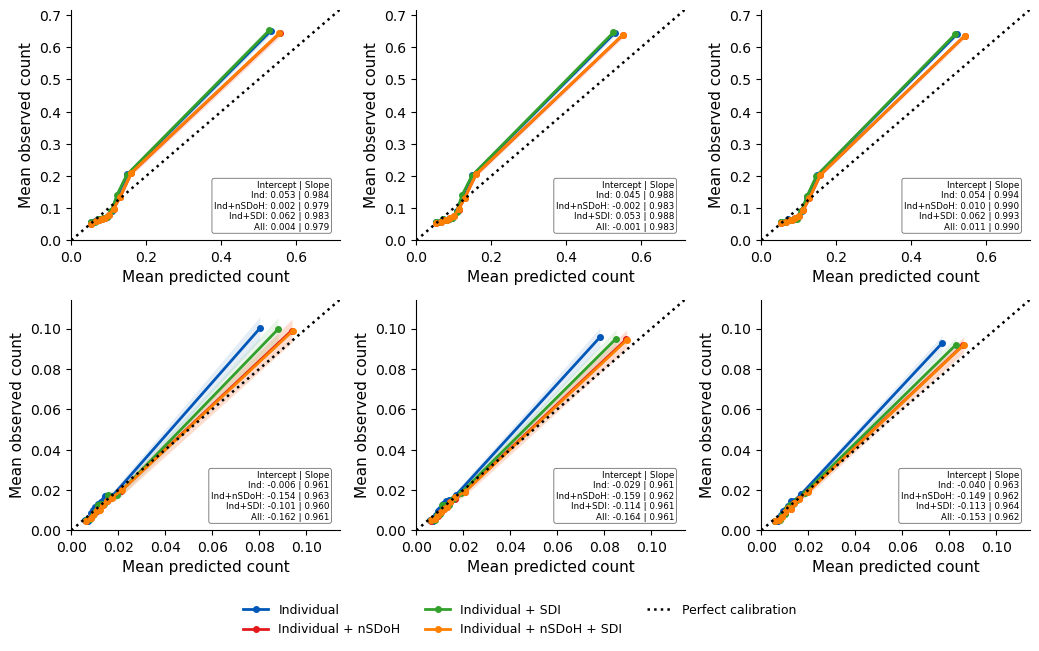

Saved plot: ../results/poisson_intensity_sample/poisson_calibration_top_10_15_20_sensitivity_all_models.png
Saved metrics: ../results/poisson_intensity_sample/poisson_calibration_top_10_15_20_sensitivity_metrics.csv


,N,mean_observed,mean_predicted,observed_to_predicted_ratio,calibration_intercept,intercept_ci_lower,intercept_ci_upper,calibration_slope,slope_ci_lower,slope_ci_upper,Outcome,Sample,Top percent,Cutoff,Model
0,137122,0.147737,0.136514,1.082212,0.053009,0.025698,0.080320,0.983705,0.969526,0.997884,PCP,Top 10% neighborhood SDoH burden,10,1.126239,Individual
1,137122,0.147737,0.142687,1.035392,0.002257,-0.024531,0.029045,0.979017,0.964859,0.993176,PCP,Top 10% neighborhood SDoH burden,10,1.126239,Individual + nSDoH
2,137122,0.147737,0.135256,1.092279,0.061713,0.034287,0.089138,0.983451,0.969273,0.997628,PCP,Top 10% neighborhood SDoH burden,10,1.126239,Individual + SDI
3,137122,0.147737,0.142516,1.036633,0.003637,-0.023163,0.030437,0.979151,0.964993,0.993308,PCP,Top 10% neighborhood SDoH burden,10,1.126239,Individual + nSDoH + SDI
4,203587,0.145613,0.136522,1.066592,0.045084,0.022298,0.067871,0.987852,0.976003,0.999701,PCP,Top 15% neighborhood SDoH burden,15,1.011837,Individual
5,203587,0.145613,0.142154,1.024338,-0.001788,-0.024193,0.020616,0.983372,0.971518,0.995226,PCP,Top 15% neighborhood SDoH burden,15,1.011837,Individual + nSDoH
6,203587,0.145613,0.135368,1.075683,0.052909,0.030037,0.075782,0.987501,0.975654,0.999349,PCP,Top 15% neighborhood SDoH burden,15,1.011837,Individual + SDI
7,203587,0.145613,0.142026,1.025259,-0.000721,-0.023134,0.021691,0.983489,0.971635,0.995343,PCP,Top 15% neighborhood SDoH burden,15,1.011837,Individual + nSDoH + SDI
8,272831,0.144533,0.135528,1.066440,0.054225,0.034273,0.074176,0.993705,0.983369,1.004041,PCP,Top 20% neighborhood SDoH burden,20,0.924106,Individual
9,272831,0.144533,0.140785,1.026621,0.010173,-0.009447,0.029793,0.989710,0.979380,1.000040,PCP,Top 20% neighborhood SDoH burden,20,0.924106,Individual + nSDoH


In [55]:
cutoff_sensitivity_calibration_metrics = plot_calibration_top_cutoff_sensitivity(
    analyses=POISSON_ANALYSES,
    top_percents=[10, 15, 20],
    model_order=MODEL_ORDER,
    n_bins=10,
    save_dir=SAVE_DIR,
    same_axis_all_panels=False
)

In [28]:
def plot_nsdoh_distribution_paper_style(
    outcome_key,
    analysis,
    save_dir=SAVE_DIR
):
    score = np.asarray(analysis["pfa_score"])
    score = score[np.isfinite(score)]

    cutoff = analysis["pfa_threshold_85"]
    high_mask = score >= cutoff

    weights = np.ones_like(score) * 100 / len(score)

    fig, ax = plt.subplots(figsize=FIGSIZE_SINGLE)

    bins = np.linspace(
        np.percentile(score, 0.5),
        np.percentile(score, 99.5),
        60
    )

    ax.hist(
        score,
        bins=bins,
        weights=weights,
        color="#7A7A7A",
        alpha=0.65,
        edgecolor="none",
        label="2019 test observations"
    )

    ax.axvspan(
        cutoff,
        bins[-1],
        color=GROUP_COLORS["Top neighborhood SDoH burden"],
        alpha=0.18,
        label="Top 15% neighborhood SDoH burden"
    )

    ax.axvline(
        cutoff,
        linestyle="--",
        linewidth=1.8,
        color="black",
        label="85th percentile cutoff"
    )

    ax.set_xlabel("Composite neighborhood SDoH burden score", fontsize=AXIS_LABEL_SIZE)
    ax.set_ylabel("Percent of observations", fontsize=AXIS_LABEL_SIZE)

    apply_paper_style(ax)

    ax.legend(
        frameon=False,
        fontsize=LEGEND_SIZE,
        loc="best"
    )

    fig.tight_layout()

    plot_path = os.path.join(
        save_dir,
        f"{outcome_key.lower()}_nsdoh_distribution_paper_style.png"
    )

    fig.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()

    summary = {
        "Outcome": outcome_key,
        "N total": len(score),
        "N top 15%": int(high_mask.sum()),
        "Percent top 15% in test": high_mask.mean() * 100,
        "85th percentile cutoff": cutoff,
        "Mean score": score.mean(),
        "Median score": np.median(score)
    }

    return summary

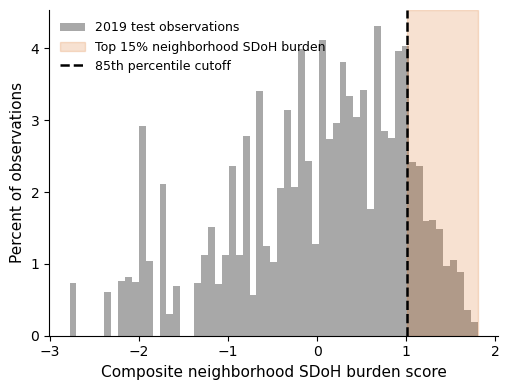

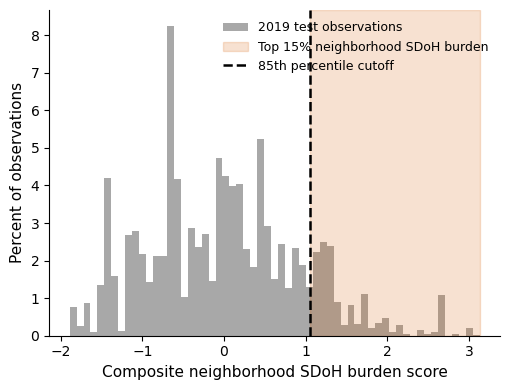

,Outcome,N total,N top 15%,Percent top 15% in test,85th percentile cutoff,Mean score,Median score
0,PCP,1359597,203587,14.974070,1.011837,0.001711,0.153406
1,ER,1359597,202745,14.912139,1.053694,-0.000236,-0.030429


In [53]:
pcp_dist_summary = plot_nsdoh_distribution_paper_style(
    outcome_key="PCP",
    analysis=POISSON_ANALYSES["PCP"]
)

er_dist_summary = plot_nsdoh_distribution_paper_style(
    outcome_key="ER",
    analysis=POISSON_ANALYSES["ER"]
)

nsdoh_distribution_summary = pd.DataFrame([
    pcp_dist_summary,
    er_dist_summary
])

display(nsdoh_distribution_summary)

In [28]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ============================================================
# nSDoH distribution: 1 x 2 paper-style panel
# ============================================================

DIST_COLOR_ALL = "#0057B8"      # blue
DIST_COLOR_TOP = "#E31A1C"      # red
DIST_COLOR_CUTOFF = "#000000"   # black


def plot_nsdoh_distribution_1x2(
    analyses,
    save_dir=SAVE_DIR,
    bins=60
):
    """
    Creates a single-row, two-panel nSDoH score distribution figure:
    left = PCP nSDoH score distribution
    right = ER nSDoH score distribution

    Bars show percent of observations.
    Red shaded region shows top 15% neighborhood SDoH burden.
    Black dashed line shows the 85th percentile cutoff.
    """

    outcome_order = ["PCP", "ER"]

    # --------------------------------------------------------
    # Get shared x-axis range across PCP and ER
    # --------------------------------------------------------

    all_scores = []

    for outcome_key in outcome_order:
        score = np.asarray(analyses[outcome_key]["pfa_score"])
        score = score[np.isfinite(score)]
        all_scores.append(score)

    combined_score = np.concatenate(all_scores)

    x_min = np.percentile(combined_score, 0.5)
    x_max = np.percentile(combined_score, 99.5)

    bin_edges = np.linspace(x_min, x_max, bins)

    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(8.2, 3.6),
        sharex=True,
        sharey=True
    )

    summary_rows = []

    for ax, outcome_key, panel_label in zip(
        axes,
        outcome_order,
        ["a", "b"]
    ):
        analysis = analyses[outcome_key]

        score = np.asarray(analysis["pfa_score"])
        score = score[np.isfinite(score)]

        cutoff = analysis["pfa_threshold_85"]
        top_mask = score >= cutoff

        weights = np.ones_like(score) * 100 / len(score)

        # Histogram bars
        ax.hist(
            score,
            bins=bin_edges,
            weights=weights,
            color=DIST_COLOR_ALL,
            alpha=0.75,
            edgecolor="white",
            linewidth=0.3
        )

        # Top 15% shaded region
        ax.axvspan(
            cutoff,
            x_max,
            color=DIST_COLOR_TOP,
            alpha=0.20,
            linewidth=0
        )

        # 85th percentile cutoff
        ax.axvline(
            cutoff,
            linestyle="--",
            linewidth=1.8,
            color=DIST_COLOR_CUTOFF
        )

        # Paper-style panel label, not title
        ax.text(
            0.02,
            0.96,
            panel_label,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            fontweight="bold"
        )

        ax.set_xlabel(
            "Composite neighborhood SDoH burden score",
            fontsize=AXIS_LABEL_SIZE
        )

        apply_paper_style(ax)

        summary_rows.append({
            "Outcome": outcome_key,
            "N total": len(score),
            "N top 15%": int(top_mask.sum()),
            "Percent top 15%": top_mask.mean() * 100,
            "85th percentile cutoff": cutoff,
            "Mean score": score.mean(),
            "Median score": np.median(score)
        })

    axes[0].set_ylabel(
        "Percent of observations",
        fontsize=AXIS_LABEL_SIZE
    )

    # --------------------------------------------------------
    # Single shared legend
    # --------------------------------------------------------

    legend_handles = [
        Patch(
            facecolor=DIST_COLOR_ALL,
            edgecolor="none",
            alpha=0.75,
            label="2019 test observations"
        ),
        Patch(
            facecolor=DIST_COLOR_TOP,
            edgecolor="none",
            alpha=0.20,
            label="Top 15% neighborhood SDoH burden"
        ),
        Line2D(
            [0],
            [0],
            color=DIST_COLOR_CUTOFF,
            linestyle="--",
            linewidth=1.8,
            label="85th percentile cutoff"
        )
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=LEGEND_SIZE,
        bbox_to_anchor=(0.5, -0.04)
    )

    fig.tight_layout(rect=[0, 0.12, 1, 1])

    plot_path = os.path.join(
        save_dir,
        "nsdoh_score_distribution_1x2.png"
    )

    fig.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    summary_df = pd.DataFrame(summary_rows)

    summary_path = os.path.join(
        save_dir,
        "nsdoh_score_distribution_1x2_summary.csv"
    )

    summary_df.to_csv(summary_path, index=False)

    print("Saved plot:", plot_path)
    print("Saved summary:", summary_path)

    display(summary_df)

    return summary_df

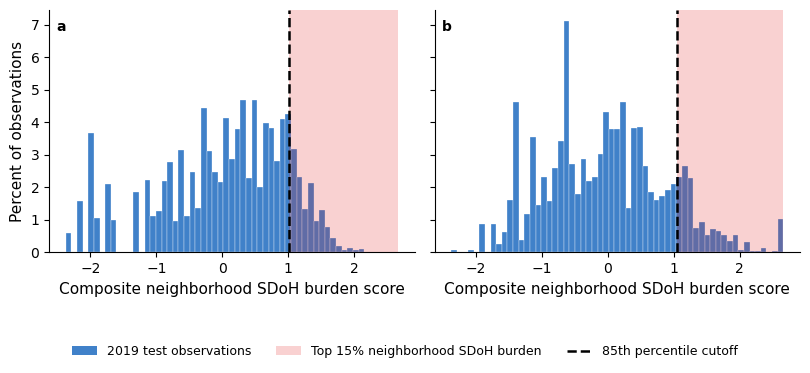

Saved plot: ../results/poisson_intensity_sample/nsdoh_score_distribution_1x2.png
Saved summary: ../results/poisson_intensity_sample/nsdoh_score_distribution_1x2_summary.csv


,Outcome,N total,N top 15%,Percent top 15%,85th percentile cutoff,Mean score,Median score
0,PCP,1359597,203587,14.974070,1.011837,0.001711,0.153406
1,ER,1359597,202745,14.912139,1.053683,-0.000236,-0.030430


In [29]:
nsdoh_distribution_summary = plot_nsdoh_distribution_1x2(
    analyses=POISSON_ANALYSES,
    save_dir=SAVE_DIR,
    bins=60
)

In [30]:
# ============================================================
# Interaction model
#
# Observed count ~ predicted clinical risk
#                + high nSDoH
#                + predicted clinical risk × high nSDoH
# ============================================================

def fit_risk_nsdoh_interaction(
    observed_count,
    predicted_count,
    high_nsdoh,
    outcome_label
):
    observed_count = np.asarray(
        observed_count,
        dtype=float
    )

    predicted_count = np.asarray(
        predicted_count,
        dtype=float
    )

    high_nsdoh = np.asarray(
        high_nsdoh,
        dtype=int
    )

    if not (
        len(observed_count)
        == len(predicted_count)
        == len(high_nsdoh)
    ):
        raise ValueError(
            f"{outcome_label}: observed count, prediction and "
            "nSDoH group have different lengths."
        )

    interaction_df = pd.DataFrame({
        "observed_count": observed_count,
        "predicted_count": predicted_count,
        "high_nsdoh": high_nsdoh
    })

    interaction_df = (
        interaction_df
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .copy()
    )

    interaction_df = interaction_df[
        (interaction_df["observed_count"] >= 0)
        & (interaction_df["predicted_count"] >= 0)
    ].copy()

    # Predicted counts are highly right-skewed, so use log1p first
    interaction_df["log_predicted_risk"] = np.log1p(
        interaction_df["predicted_count"]
    )

    risk_mean = interaction_df[
        "log_predicted_risk"
    ].mean()

    risk_std = interaction_df[
        "log_predicted_risk"
    ].std()

    if risk_std == 0:
        raise ValueError(
            f"{outcome_label}: predicted risk has no variation."
        )

    # Standardized clinical risk
    interaction_df["predicted_risk_z"] = (
        interaction_df["log_predicted_risk"] - risk_mean
    ) / risk_std

    # Interaction term
    interaction_df["risk_x_high_nsdoh"] = (
        interaction_df["predicted_risk_z"]
        * interaction_df["high_nsdoh"]
    )

    X_interaction = interaction_df[
        [
            "predicted_risk_z",
            "high_nsdoh",
            "risk_x_high_nsdoh"
        ]
    ].copy()

    X_interaction = sm.add_constant(
        X_interaction,
        has_constant="add"
    )

    model = sm.GLM(
        interaction_df["observed_count"],
        X_interaction,
        family=sm.families.Poisson()
    )

    # Robust standard errors help with possible overdispersion
    result = model.fit(
        cov_type="HC0",
        maxiter=100
    )

    print("\n" + "=" * 75)
    print(outcome_label)
    print("=" * 75)

    print(
        "Number of observations:",
        f"{len(interaction_df):,}"
    )

    print(
        "Top 15% nSDoH group:",
        round(
            interaction_df["high_nsdoh"].mean() * 100,
            2
        ),
        "%"
    )

    print(result.summary())

    return {
        "result": result,
        "data": interaction_df,
        "risk_mean": risk_mean,
        "risk_std": risk_std
    }

In [31]:
pcp_interaction_result = fit_risk_nsdoh_interaction(
    observed_count=POISSON_ANALYSES["PCP"]["observed"],
    predicted_count=POISSON_ANALYSES["PCP"]["predictions"]["individual"],
    high_nsdoh=(
        POISSON_ANALYSES["PCP"]["pfa_score"]
        >= POISSON_ANALYSES["PCP"]["pfa_threshold_85"]
    ).astype(int),
    outcome_label="PCP count"
)

er_interaction_result = fit_risk_nsdoh_interaction(
    observed_count=POISSON_ANALYSES["ER"]["observed"],
    predicted_count=POISSON_ANALYSES["ER"]["predictions"]["individual"],
    high_nsdoh=(
        POISSON_ANALYSES["ER"]["pfa_score"]
        >= POISSON_ANALYSES["ER"]["pfa_threshold_85"]
    ).astype(int),
    outcome_label="ER count"
)


PCP count
Number of observations: 1,359,597
Top 15% nSDoH group: 14.97 %
                 Generalized Linear Model Regression Results                  
Dep. Variable:         observed_count   No. Observations:              1359597
Model:                            GLM   Df Residuals:                  1359593
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -5.4903e+05
Date:                Fri, 17 Jul 2026   Deviance:                   7.4926e+05
Time:                        19:50:56   Pearson chi2:                 1.42e+06
No. Iterations:                     9   Pseudo R-squ. (CS):            0.05761
Covariance Type:                  HC0                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------